In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    r"C:\Users\LENOVO\Desktop\csv_datasheets\Listings.csv",
    encoding="latin-1",
    low_memory=False,
)

Cleaning Data 

In [3]:
df['host_since'] = pd.to_datetime(df['host_since'])
df['price'] = df['price'].astype(float)
df[['host_is_superhost','host_has_profile_pic','host_identity_verified','instant_bookable']] = df[['host_is_superhost','host_has_profile_pic','host_identity_verified','instant_bookable']].astype(bool)

#drop duplicate
df = df.drop_duplicates(subset= 'listing_id')

Making Plots

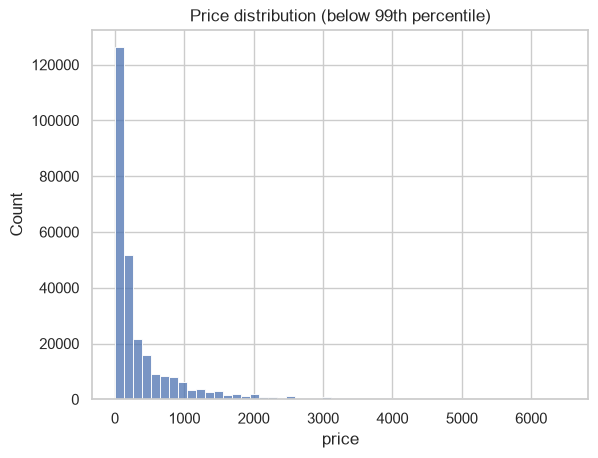

In [8]:
sns.set_theme(style="whitegrid")

df["price"].describe()
sns.histplot(df[df["price"] < df["price"].quantile(0.99)]["price"], bins=50)
plt.title("Price distribution (below 99th percentile)")
plt.show()

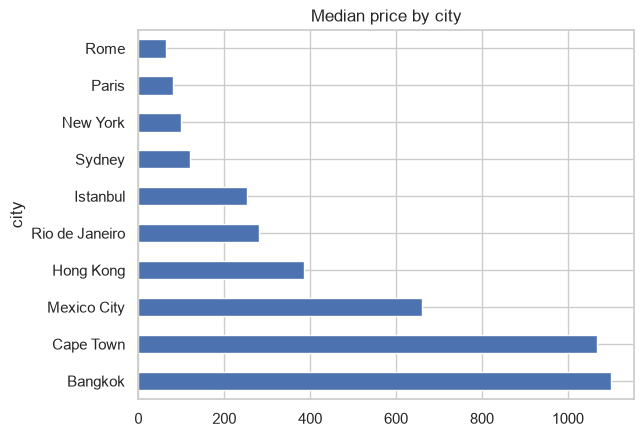

In [22]:
top_cities = df.groupby("city")["price"].median().sort_values(ascending=False).head(10)
top_cities.plot(kind="barh")
plt.title("Median price by city")
plt.show()

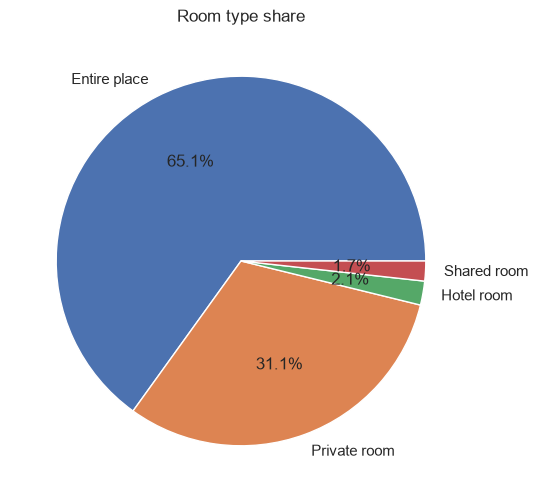

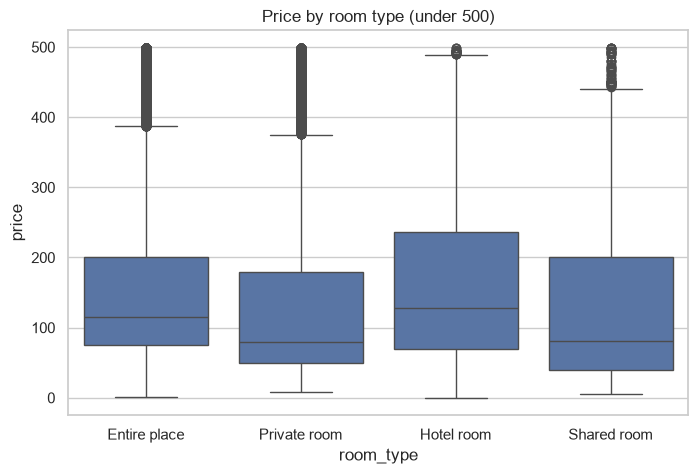

In [23]:
# Pie chart
plt.figure(figsize=(6, 6))
df["room_type"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.ylabel("")
plt.title("Room type share")
plt.show()

# Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[df["price"] < 500], x="room_type", y="price")
plt.title("Price by room type (under 500)")
plt.show()

<Axes: xlabel='host_year'>

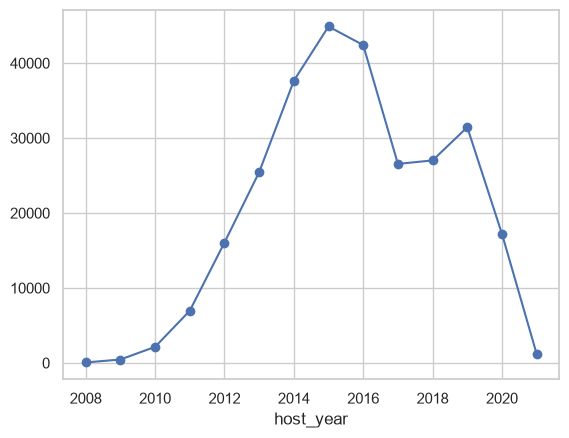

In [13]:
df["host_year"] = df["host_since"].dt.year
df["host_year"].value_counts().sort_index().plot(kind="line", marker="o")